# 01 - Cohort and QC

Before any modelling: does this look like cfDNA, and does anything separate
the groups for reasons that are not disease?

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../src'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from cfdna_insight.features import load_features, split_legacy_technical

FEATURES = '../results/features'

# split_legacy_technical moves chromosome entropy and coverage dispersion out
# of the technical block. They are copy-number readouts, and leaving them in
# the negative control makes it fire for biological reasons.
blocks = split_legacy_technical(load_features(FEATURES))

samples = pd.read_csv(os.path.join(FEATURES, 'samples_used.tsv'), sep='\t')
order = [s for s in samples['sample_id'] if s in blocks['size_summary'].index]
samples = samples.set_index('sample_id').loc[order].reset_index()
y = (samples['label'] == 'cancer').astype(int).to_numpy()

print(f'{len(order)} samples, {y.sum()} cancer, {len(y)-y.sum()} control')
{k: v.shape for k, v in blocks.items()}

[info] moved ['tech_chr_entropy', 'tech_coverage_cv'] from technical -> aneuploidy (they are copy-number readouts, not library metrics)
66 samples, 33 cancer, 33 control


{'coverage': (66, 550),
 'delfi': (66, 550),
 'motif': (66, 256),
 'size_hist': (66, 351),
 'size_summary': (66, 10),
 'technical': (66, 4),
 'window_arms': (66, 550),
 'aneuploidy': (66, 2)}

## Cohort

33 matched pairs. Each control is matched to its case on age, sex, smoking
and alcohol, and the two were processed in the same library-prep and
sequencing batch.

In [2]:
for col in ['cancer_type', 'seq_batch', 'gender']:
    if col in samples.columns:
        print(pd.crosstab(samples['label'], samples[col]), '\n')

cancer_type  breast  liver
label                     
cancer           25      8
healthy          25      8 

seq_batch  Cabat1  Cabat2  Cabat3  Cabat4  Cabat5
label                                            
cancer          9       9       6       4       5
healthy         9       9       6       4       5 

gender   Female  Male
label                
cancer       28     5
healthy      28     5 



### Is batch confounded with label?

The usual failure mode in public cfDNA data is cases collected
prospectively in clinic and controls pulled from a biobank, which makes
batch a proxy for label. Here it is not: every pair shares a batch.

In [3]:
if 'seq_batch' in samples.columns and 'pair_id' in samples.columns:
    split = samples.groupby('pair_id')['seq_batch'].nunique()
    print(f'pairs whose case and control are in different batches: {(split > 1).sum()} of {len(split)}')
    print()
    print(pd.crosstab(samples['seq_batch'], samples['label']))

pairs whose case and control are in different batches: 0 of 33

label      cancer  healthy
seq_batch                 
Cabat1          9        9
Cabat2          9        9
Cabat3          6        6
Cabat4          4        4
Cabat5          5        5


## Sequencing depth

If cases were sequenced deeper than controls, every count-based feature is
confounded. Tested two ways: across the cohort, and within pair.

In [4]:
from scipy.stats import mannwhitneyu, wilcoxon

tech = blocks['technical'].reindex(order)
depth = tech['tech_n_fragments']
print(depth.groupby(samples['label'].to_numpy()).describe().round(0))

u, p = mannwhitneyu(depth[y == 1], depth[y == 0])
print(f'\nacross cohort: p = {p:.3g}')

d = tech.join(samples.set_index('sample_id')[['pair_id', 'label']])
piv = d.pivot_table(index='pair_id', columns='label',
                    values='tech_n_fragments').dropna()
_, pp = wilcoxon(piv['cancer'], piv['healthy'])
n_hi = int((piv['cancer'] > piv['healthy']).sum())
print(f'within pair:   case deeper in {n_hi}/{len(piv)} pairs, p = {pp:.3g}')

         count        mean         std        min         25%         50%  \
cancer    33.0  23370261.0  12222874.0  1406889.0  15962608.0  23313237.0   
healthy   33.0  27924550.0  15643594.0  1837644.0  18600588.0  25970437.0   

                75%         max  
cancer   30066772.0  55489693.0  
healthy  34640659.0  61152299.0  

across cohort: p = 0.305
within pair:   case deeper in 16/33 pairs, p = 0.339


Depth is null in both tests, so count-based features are not reading it.

## Fragment size distributions

What a cfDNA library should look like: a peak near 167 bp (147 bp wrapped
on the nucleosome plus linker) and a 10 bp ripple from the helical pitch of
DNA on the histone octamer. A sample missing either has been degraded.

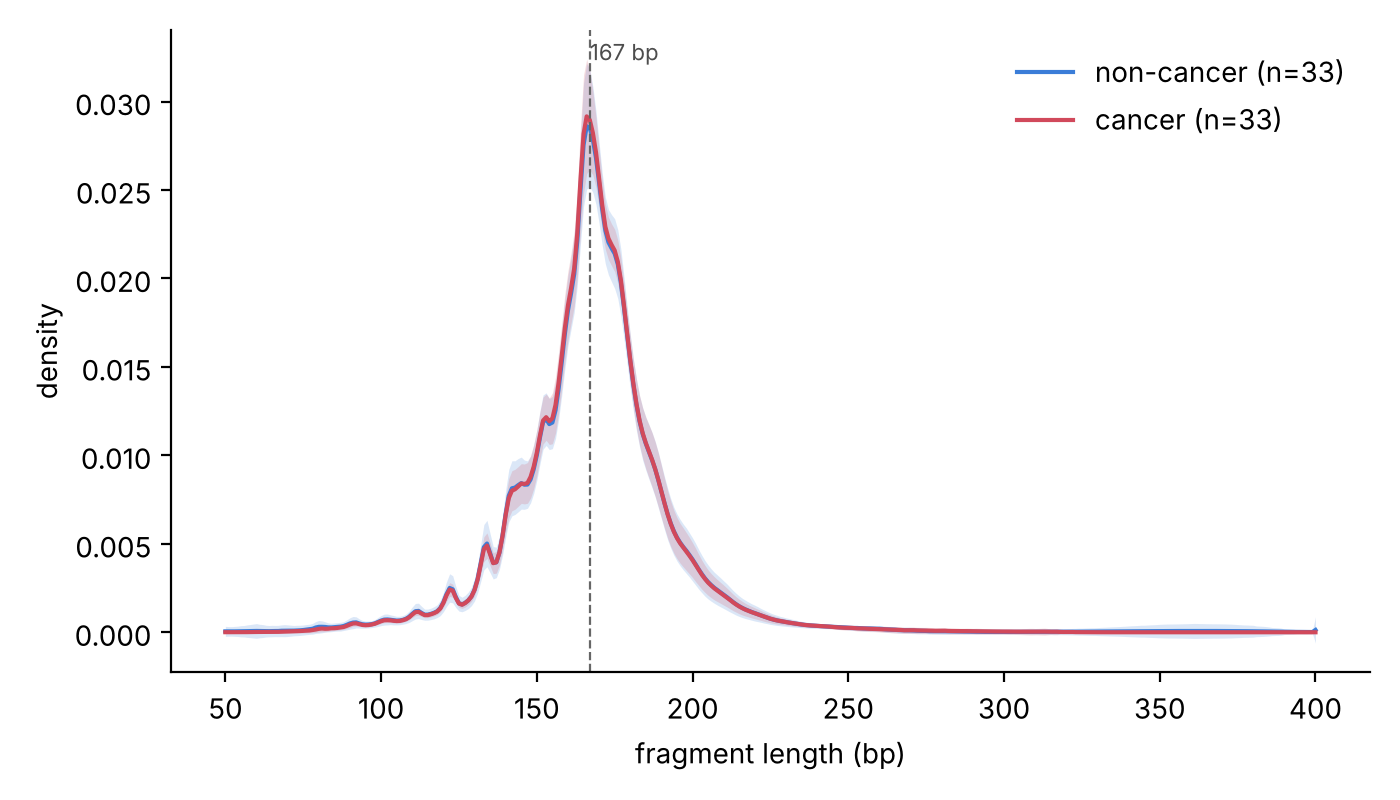

In [5]:
from cfdna_insight.plots import plot_size_distributions
from IPython.display import Image
plot_size_distributions(blocks['size_hist'].reindex(order), y,
                        '/tmp/sizes.png')
Image('/tmp/sizes.png')

The two curves sit on top of each other. That is the first sign of the
main negative result in this project, before any model is fit.

In [6]:
summ = blocks['size_summary'].reindex(order)
low = summ['periodicity_10bp'] < summ['periodicity_10bp'].quantile(0.05)
print('lowest-periodicity samples (degradation candidates):')
print(samples.loc[low.to_numpy(), ['sample_id', 'label', 'seq_batch']]
      .to_string(index=False))

lowest-periodicity samples (degradation candidates):
sample_id   label seq_batch
 MAL0642m healthy    Cabat3
  MAL0728  cancer    Cabat1
 MAL0883m healthy    Cabat5
 MAL0714m healthy    Cabat3
